# 05 — Optional ML + XAI Extension (Random Forest LST prediction + SHAP)

**Status: optional extension.** The core study's contribution is the GIS/remote-sensing
methodology (HEI + Getis-Ord Gi*); this ML layer supplements it with a driver-attribution
experiment and does **not** replace any core result. Produced by `src/model.py` and
`src/shap_analysis.py` (both intentionally untracked, per `src/_MODEL_LAYER_NOTE.md`).
This notebook is read-only: it displays existing outputs from `outputs/` and retrains nothing.

## ML objective

Predict Landsat-derived LST (°C) per 100 m land cell from surface/population covariates,
then use SHAP to rank which covariates the model attributes its predictions to. The
interesting output is the **attribution ranking**, not the R² — this is driver attribution,
not an operational LST-prediction product.

Two feature sets are compared **on identical splits** (same seed, same 1 km block assignment):

- **base** — NDVI, NDBI, GHSL built-up, WorldPop density, WorldCover class (one-hot).
- **extended** — base + five physically-motivated spatial-context features:
  - **3×3 (300 m) focal means** of the four continuous predictors. A 100 m cell's surface
    temperature responds to the surrounding surface (source-area/advection effect), not just
    the cell itself. These are NaN-aware neighbourhood means of *predictor* rasters only —
    they never touch the LST target, so they cannot leak the target across the train/test
    block boundary.
  - **`dist_water_m`** — distance to the nearest non-land cell (distance transform of
    `land_mask`), i.e. proximity to sea/lagoon cooling. This realises the `dist_water`
    predictor listed in `config.yaml`'s original `optional_model` block.

Design safeguards (full rationale in `reports/experiment_log.md`, 2026-07-11 entries):
- Dataset = the exact HEI analysis universe (n = 5,391 complete-case land cells).
- **Raw x/y coordinates excluded from features** (with Moran's I = 0.80, a tree would
  memorise location and launder autocorrelation as "importance"); used only to build blocks.
- **Spatial block split is the honest headline** (whole 1 km blocks held out, 75/15);
  the naive random split is reported only to quantify leakage.
- Fixed modest RF hyperparameters, no tuning; determinism check confirmed the recomputed
  base rows reproduce the recorded baseline exactly.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

import pandas as pd
from IPython.display import Image, display

TABLES = ROOT / "outputs" / "tables"
FIGURES = ROOT / "outputs" / "figures"

## Model performance — baseline vs improved

In [2]:
metrics = pd.read_csv(TABLES / "ml_metrics.csv")
metrics.round(3)

,split,feature_set,model,r2,rmse,mae
0,random,base,baseline_mean,-0.001,1.975,1.412
1,random,base,linear_regression,0.628,1.204,0.931
2,random,base,random_forest,0.699,1.083,0.822
3,spatial_block,base,baseline_mean,-0.116,2.295,1.727
4,spatial_block,base,linear_regression,0.643,1.297,0.978
5,spatial_block,base,random_forest,0.656,1.274,0.976
6,spatial_block,base,random_forest_no_ndbi,0.569,1.426,1.077
7,block_groupkfold_5fold,base,random_forest,0.604,NaN,NaN
8,random,extended,random_forest,0.783,0.920,0.709
9,random,extended,linear_regression,0.661,1.149,0.889


In [3]:
# Headline comparison: RF on the spatial-block test set, base vs extended features
headline = metrics[
    (metrics["model"] == "random_forest")
    & metrics["split"].isin(["spatial_block", "block_groupkfold_5fold"])
][["split", "feature_set", "r2", "rmse", "mae"]]
headline.round(3)

,split,feature_set,r2,rmse,mae
5,spatial_block,base,0.656,1.274,0.976
7,block_groupkfold_5fold,base,0.604,NaN,NaN
10,spatial_block,extended,0.765,1.054,0.792
14,block_groupkfold_5fold,extended,0.686,NaN,NaN


Reading the table:

- **Improved headline (extended features, spatial block split): RF R² = 0.765,
  RMSE = 1.05 °C, MAE = 0.79 °C** — up from the base-feature baseline (R² = 0.656,
  RMSE = 1.27 °C, MAE = 0.98 °C) on the *identical* held-out blocks: **+0.11 R²,
  −0.22 °C RMSE**. The block 5-fold GroupKFold confirms the gain is not split luck
  (0.686 ± 0.095 vs 0.604 ± 0.090).
- **The features matter, not the model class**: HistGradientBoosting on the same extended
  features scores R² = 0.760 ≈ RF's 0.765, and extended linear regression reaches 0.727.
  The improvement comes from giving the model 300 m spatial context, not from a fancier
  algorithm — the right framing for the paper.
- **Leakage check still holds**: random-split R² (0.783) exceeds the spatial-split R²
  (0.765) — the gap is the inflation a naive random split would have hidden.
- **NDBI ablation, extended**: removing NDBI (cell + focal) still leaves R² = 0.682 —
  which *exceeds the full base-feature baseline* (0.656). The improvement is therefore not
  riding on the quasi-circular predictor (caveat below).

## Predicted vs. observed (extended RF, spatial test set)

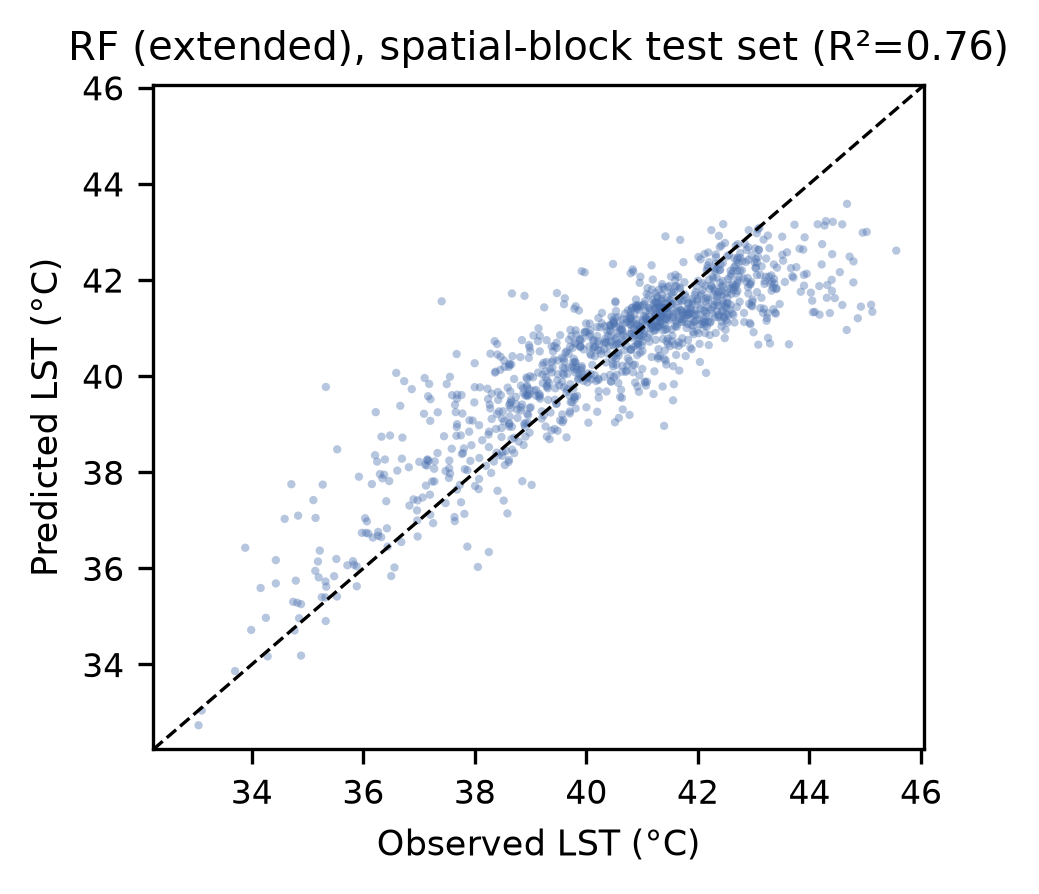

In [4]:
display(Image(filename=str(FIGURES / "ml_pred_vs_obs.png")))

**Caption**: extended-feature RF predictions on the 1,100 held-out spatial-test cells.
Scatter is visibly tighter around the 1:1 line than the baseline model's; mild
under-prediction of the hottest cells and over-prediction of the coolest remains (tree
ensembles compress distribution edges).

## SHAP attribution (extended RF, spatial test set only)

In [5]:
shap_imp = pd.read_csv(TABLES / "shap_importance.csv")
shap_imp[shap_imp["level"] == "headline_aggregated"][["feature", "mean_abs_shap"]].round(3)

,feature,mean_abs_shap
0,ndbi_foc3,0.360
1,ndbi,0.355
2,ndvi_foc3,0.197
3,dist_water_m,0.151
4,ndvi,0.135
5,built_up_foc3,0.119
6,pop_density_foc3,0.113
7,pop_density,0.086
8,lulc_class (all),0.075
9,built_up,0.039


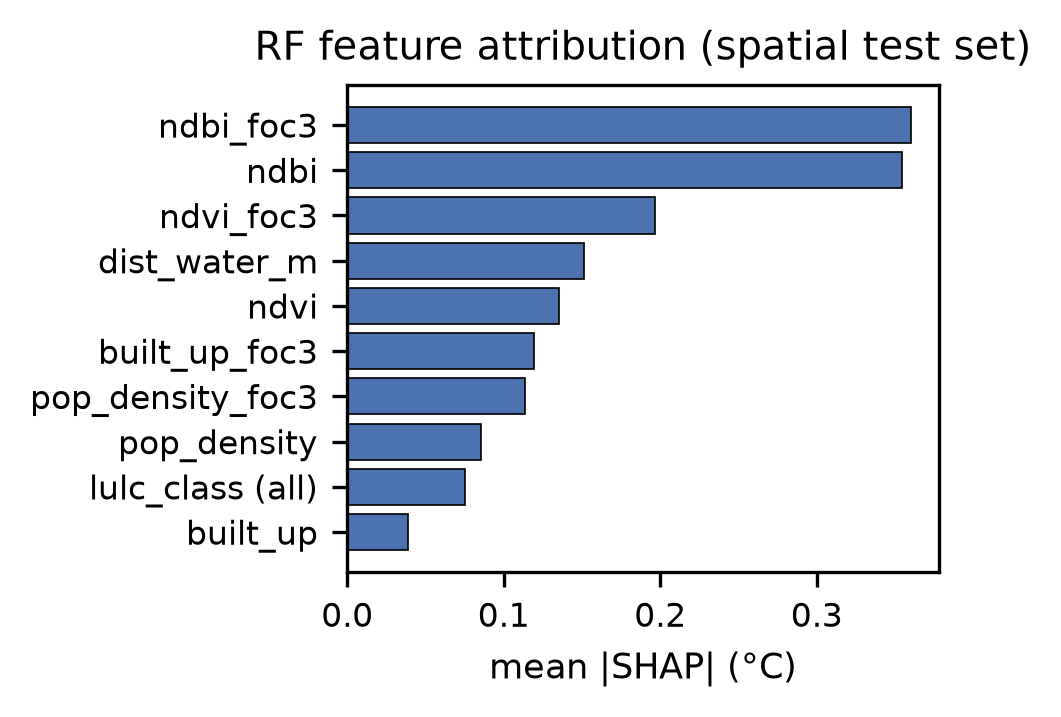

In [6]:
display(Image(filename=str(FIGURES / "shap_bar.png")))

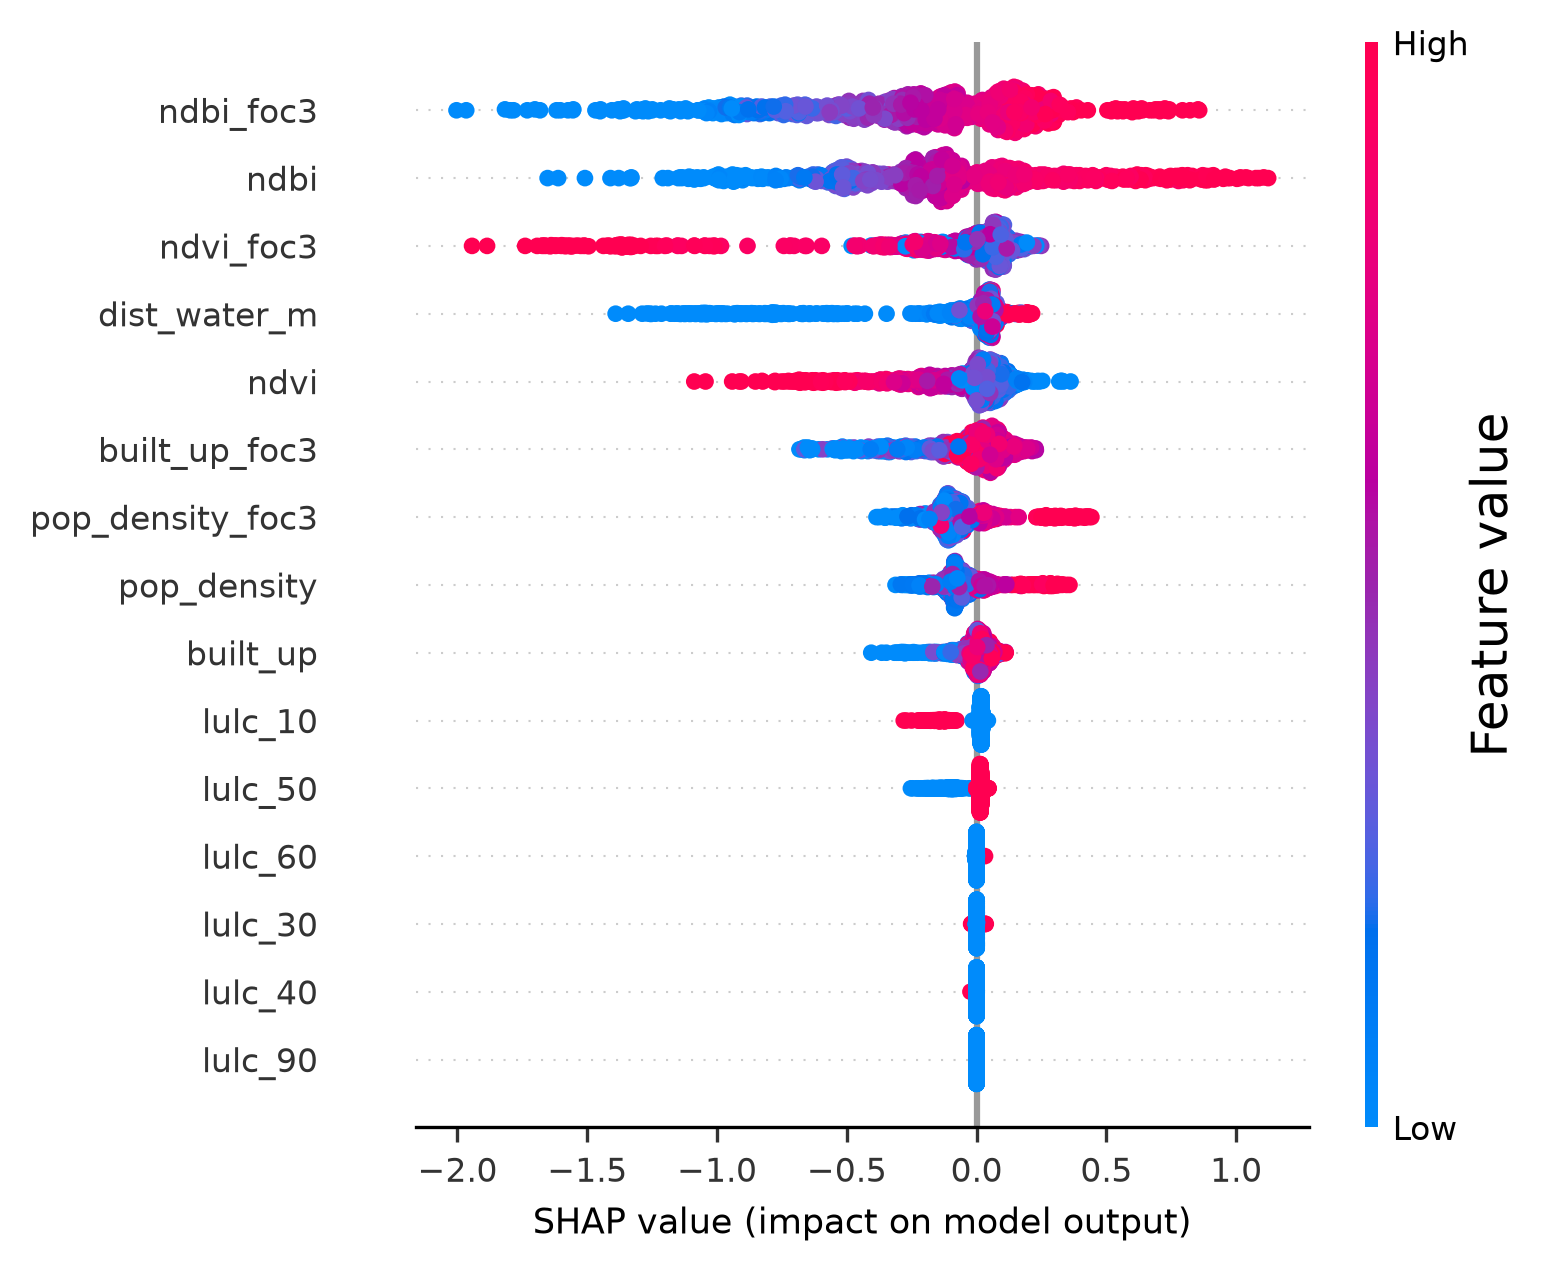

In [7]:
display(Image(filename=str(FIGURES / "shap_summary.png")))

**Caption**: mean-|SHAP| ranking (bar; one-hot land-cover classes aggregated) and beeswarm
(per-cell attributions, colour = feature value), computed on the spatial test set.

Key attribution findings:

1. **Neighbourhood context outranks cell values.** `ndbi_foc3` (0.360 °C) edges out
   cell-level `ndbi` (0.355), and `ndvi_foc3` (0.197) clearly outranks cell `ndvi` (0.135).
   The model consistently prefers the 300 m-context versions of the drivers — consistent
   with LST at 100 m integrating heat from the surrounding surface, not just the pixel.
2. **Distance to water ranks 4th** (0.151 °C): cells nearer the sea/lagoon are attributed
   cooler predictions, physically consistent with coastal moderation of surface temperature.
   (Interpret as *proximity association*, not a measured sea-breeze mechanism — the feature
   is geometric, and it may also absorb other coast-correlated gradients.)
3. **Directions remain coherent** with the core correlation analysis: high built-up-ness
   pushes predictions warmer, high vegetation cooler, high population density warmer.
4. Cell-level `built_up` (GHSL) drops to last (0.039) — largely displaced by its own focal
   version and NDBI, consistent with its weaker/different-vintage signal noted in the
   core study.

## Interpretation and limitations

1. **SHAP ranks model attributions, not physical causes.** The ranking says what the RF
   uses to predict LST — evidence about association structure, not a causal decomposition
   of the urban heat island.
2. **NDBI is quasi-circular.** Both `ndbi` and `ndbi_foc3` derive from the *same 2024
   Landsat composite* as the LST target, so part of their combined dominance reflects shared
   sensor/scene rather than an independent physical driver. The ablation bounds this
   honestly: without either NDBI feature, extended R² = 0.682 — still above the full
   base-feature baseline — so the model is not merely echoing the shared composite, but
   NDBI's top ranks must always be reported with this caveat.
3. **Focal features share the same provenance as their parents** — `ndvi_foc3` inherits
   NDVI's properties, `ndbi_foc3` inherits the NDBI caveat. Nothing new is measured; the
   improvement is spatial context on the same instruments.
4. **Spatial leakage is quantified, not assumed away** — random-vs-spatial gap ≈ 0.02 R²
   for the extended model (0.783 vs 0.765).
5. **Predictors span 2020–2024** (WorldPop/GHSL 2020, WorldCover 2021, Landsat 2024) —
   the same accepted year-mismatch limitation as the core pipeline.
6. **Tiny land-cover classes** (cropland n=9, wetland n=3) contribute noise-level SHAP
   values — do not interpret their individual attributions.

## Paper inclusion recommendation

The pre-registered criteria are met with margin: spatial-split R² = 0.765 (GroupKFold
0.686 ± 0.095), coherent SHAP ranking, quantified leakage. **Recommendation: a short
subsection or appendix.** The two strongest sentences for the paper are (a) the
random-vs-spatial leakage comparison, and (b) "neighbourhood (300 m) versions of the
drivers outrank their cell-level values, and model class barely matters once that context
is provided" — a finding about spatial scale, not about machine learning. The core
HEI/hotspot methodology remains the paper's contribution.